### Problem 18 : Recommender systems - when your taste is on every film's page

⏱️ ~40 min · 🧭 Stage 8 (Extensions), rung 12 · 📄 `resources/papers/02-exact-unlearning/2022-chen-recommendation-unlearning-receraser.pdf`, `resources/papers/04-evaluation-and-privacy/2020-chen-when-unlearning-jeopardizes-privacy.pdf`, `resources/papers/01-foundations/2015-cao-yang-towards-making-systems-forget.pdf`

> 🔗 **Building on Problems 1, 2, 7 and 17 :** so far, each person's data was one row : one digit, one census record,
> one text message. A recommender is different. It learns from what people have **in common** : "people who watched
> film A also watched film B". So your data is not in one place. It is spread over the links between all the films you
> watched. And the service shows those links to everyone, on every film's page.

A film-streaming service recommends films based on who watched what. We use real data for this : MovieLens 100K, with
943 people, 1,682 films and 100,000 ratings from 1997-98. One user, **Erin**, closes her account and asks the service
to erase her viewing history. The law gives her that right (GDPR Art. 17).

Viewing history is private. In the US, a law (the Video Privacy Protection Act, 1988) was passed after a newspaper
printed the list of films a Supreme Court nominee had rented. And in 2008, researchers showed that "anonymous" Netflix
ratings could be matched back to real, named people (Narayanan & Shmatikov 2008).

Erin has unusual taste. She watched 186 films, and 11 of them were watched by nobody else on the service.

> 🟢 **In plain words :** think of a shop assistant in a video shop who remembers what customers rent together. If one
> customer always rents rare foreign films, the assistant starts telling other customers "people who liked *this* rare
> film also liked *that* one". Every time, the assistant is repeating a piece of her rental history. Cutting up her
> membership card does not make the assistant forget.

> 🔴 **For practitioners :** two kinds of model, two answers. (1) **Item-kNN** stores how often two films are watched
> together. That is a sum over users, so removing a user is a subtraction : exact and almost free (Cao & Yang 2015,
> Problem 1). (2) **Matrix factorisation** gives every user and every film a vector, and they are all fitted together.
> Deleting the user's vector leaves her influence in the film vectors. One cheap update gets most of the way, but an
> exact answer needs a retrain, and splitting users into shards (RecEraser, Chen et al. 2022) costs quality. A trap
> that is special to recommenders : the public "also watched" lists change when someone is deleted, and the change
> itself shows what they watched (Calandrino et al. 2011; Chen et al. 2021). Batching and thresholds do not stop that.
> Fresh random noise on what is published does.

**TASK :** Train two kinds of recommender. Find where Erin is hidden in each one. Remove her, exactly and
approximately. Check every method against models that never saw her. Then attack the deletion itself.

In [1]:
# On Google Colab? Run this cell first : it fetches the course library (mul/) and the diagrams. Locally it does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.isdir("mul"):
    !git clone -q --depth 1 https://github.com/Shreyan1/machine-unlearning-course.git
    %cd machine-unlearning-course
    !pip install -q fairlearn

943 users, 1682 films, 80,000 views to learn from (20,000 held out)
Erin: 186 films, median audience 26 users (the median view on the service: a film watched by 115 users)
11 films nobody else watched: Fall (1997), For Ever Mozart (1996), Nightwatch (1997), To Have, or Not (1995), B*A*P*S (1997), Rough Magic (1995), Nothing Personal (1995), Brother's Kiss, A (1997), Ripe (1996), Next Step, The (1995), MURDER and murder (1996)


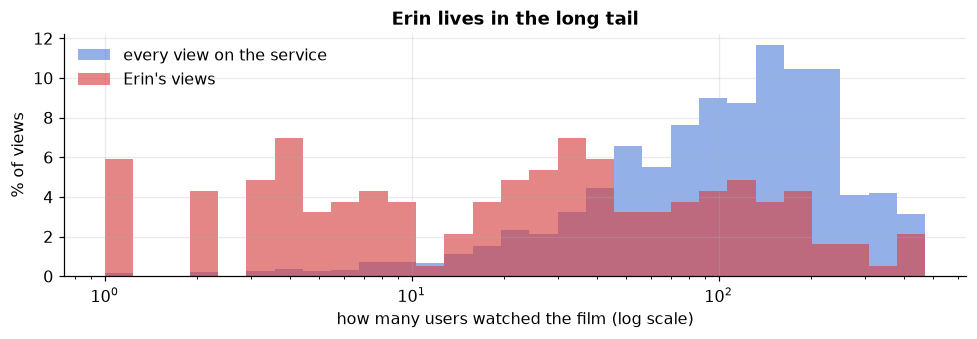

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mul import data, recsys as rs, viz
viz.style()

ratings, films = data.load_movielens()
N_USERS, N_FILMS = ratings.user.nunique(), ratings.item.nunique()
R, R_test = rs.implicit_split(ratings, N_USERS, N_FILMS)        # 80% of every user's films to learn from, 20% held out
title = films.set_index("item").title

ERIN = 781                                                       # the user who asks to be forgotten
erin = np.flatnonzero(R[ERIN])                                   # her films (in the training data)
audience = R.sum(0)                                              # how many users watched each film
only_erin = erin[audience[erin] == 1]
others = np.setdiff1d(np.arange(N_USERS), [ERIN])
R_without = R.copy(); R_without[ERIN] = 0                        # D_r : the same data, without Erin

views = np.nonzero(R)[1]
print(f"{N_USERS} users, {N_FILMS} films, {int(R.sum()):,} views to learn from ({int(R_test.sum()):,} held out)")
print(f"Erin: {len(erin)} films, median audience {np.median(audience[erin]):.0f} users "
      f"(the median view on the service: a film watched by {np.median(audience[views]):.0f} users)")
print(f"{len(only_erin)} films nobody else watched: " + ", ".join(title[only_erin]))

fig, ax = plt.subplots(figsize=(9, 3.2))
bins = np.logspace(0, np.log10(audience.max() + 1), 30)
share = lambda a: np.full(len(a), 100 / len(a))
ax.hist(audience[views], bins=bins, weights=share(views), color=viz.RETAIN, alpha=0.55, label="every view on the service")
ax.hist(audience[erin], bins=bins, weights=share(erin), color=viz.FORGET, alpha=0.65, label="Erin's views")
ax.set_xscale("log"); ax.set_ylabel("% of views"); ax.set_xlabel("how many users watched the film (log scale)")
ax.set_title("Erin lives in the long tail"); ax.legend()
plt.tight_layout(); plt.show()

Most views on the service are of films that hundreds of people watched. Half of Erin's films were watched by 26
people or fewer, and 11 by her alone. This is Carol again (Problem 4) : an unusual person is exactly the person a
model has to memorise, because nobody else looks like her.

#### Step 1 : Train - two recommenders

Both models only use *who watched what* : a 1 if a user watched a film, a 0 if not. The star rating is ignored.

To measure quality, we hid 20% of each user's films before training. A good recommender should put those hidden films
in the user's top 10. **recall@10** is the share of hidden films that made it into the top 10 (higher is better).

1. **Item-kNN** (`mul/recsys.py → ItemKNN`). The whole model is one table, `G`. `G[i, j]` counts how many users
   watched both film `i` and film `j`. Two films are "similar" when many of the same people watched them (cosine
   similarity). To recommend, the model adds up how similar each film is to the films you already watched.
2. **Matrix factorisation** (`ImplicitALS`, Hu, Koren & Volinsky 2008). Every user and every film gets a list of 32
   numbers (a vector). If a user's numbers and a film's numbers line up, the model predicts the user will like the
   film. Training takes turns : keep the film numbers fixed and find the best numbers for each user (one small ridge
   regression each, like Problem 2), then the other way round. It does this 12 times.

In [3]:
# Step 1: train both recommenders, and the baseline every recommender has to beat
knn = rs.ItemKNN().fit(R)
als = rs.ImplicitALS(seed=0).fit(R)

class MostPopular:
    def scores(self, users):
        return np.tile(audience, (len(users), 1))

print(pd.Series({"most popular films (baseline)": rs.recall_at_k(MostPopular(), R, R_test),
                 "item-kNN": rs.recall_at_k(knn, R, R_test),
                 "matrix factorisation (ALS)": rs.recall_at_k(als, R, R_test)}, name="recall@10").round(3).to_string())
print(f"\nALS: {als.k} factors x ({N_USERS} users + {N_FILMS} films) = {als.k * (N_USERS + N_FILMS):,} numbers")

most popular films (baseline)    0.210
item-kNN                         0.349
matrix factorisation (ALS)       0.423

ALS: 32 factors x (943 users + 1682 films) = 84,000 numbers


Both are much better than just showing the most popular films. Matrix factorisation is the better of the two, which is
the usual result.

#### Step 2 : Show the issue - Erin is on other people's screens

Every film on the service has a public page with a list : **"people who watched this also watched"**. It shows the 10
most similar films. Here is the page of one of the films that only Erin watched.

In [4]:
# Step 2a: the public page of a film only Erin watched
pages = rs.also_watched(knn)
f = only_erin[0]
print(f"People who watched {title[f]} also watched:")
for j in pages[f]:
    print(f"   {title[j]:32s} watched together by {int(knn.G[f, j])} user{'s' if knn.G[f, j] > 1 else ' '}"
          f"{'   <- Erin' if j in erin else ''}")

People who watched Fall (1997) also watched:
   Brother's Kiss, A (1997)         watched together by 1 user    <- Erin
   For Ever Mozart (1996)           watched together by 1 user    <- Erin
   To Have, or Not (1995)           watched together by 1 user    <- Erin
   Nightwatch (1997)                watched together by 1 user    <- Erin
   B*A*P*S (1997)                   watched together by 1 user    <- Erin
   Rough Magic (1995)               watched together by 1 user    <- Erin
   Nothing Personal (1995)          watched together by 1 user    <- Erin
   MURDER and murder (1996)         watched together by 1 user    <- Erin
   Ripe (1996)                      watched together by 1 user    <- Erin
   Next Step, The (1995)            watched together by 1 user    <- Erin


Every film on that page is one of Erin's. Each link is there because of one person : her. Anyone who opens these
pages is reading part of her viewing history. This is not a bug. It is simply what "also watched" means when only one
person watched.

Is matrix factorisation safer? It squeezes everything into 32 numbers per film, so maybe Erin gets lost. To find out
we need measurements, and something to compare with : models that **never saw Erin** (the gold band from Problem 6).
We measure three things :

- **fingerprint** : about 7,000 pairs of Erin's films are linked by *her alone* (nobody else watched both). How similar
  does the model think these pairs are? A model that never saw her has no reason to link them.
- **her pages** : look at the "also watched" pages of her rare films (10 viewers or fewer). What share of the slots
  shows her other films?
- **fold-in attack** : an outsider knows Erin's films (maybe from her public reviews). They add her to the model as if
  she were a brand-new user, the same way the service handles sign-ups. Then they check how highly the model ranks her
  films, as a percentile (1.0 = top). If the model trained on her, it ranks her films higher. This is the attack from
  Problem 5, aimed at the film numbers.

In [5]:
# Step 2b: three measurements, and the gold band from 8 models that never saw Erin
iu = np.triu_indices(len(erin), 1)
only_her_link = knn.G[np.ix_(erin, erin)][iu] == 1
PI, PJ = erin[iu[0][only_her_link]], erin[iu[1][only_her_link]]      # pairs of films linked by Erin alone
niche = erin[audience[erin] <= 10]

def measure(m):
    if isinstance(m, rs.ImplicitALS):
        x = m.solve(R[[ERIN]], m.Y)[0]                                # the attacker's fold-in: solve her vector
        s = m.Y @ x
    else:
        s = R[ERIN] @ m.similarity()
    return {"fingerprint": m.item_similarity()[PI, PJ].mean(),
            "her pages": np.isin(rs.also_watched(m)[niche], erin).mean(),
            "fold-in attack": np.mean([(s < s[i]).mean() for i in erin]),
            "recall@10 (others)": rs.recall_at_k(m, R, R_test, users=others)}

IN = pd.DataFrame([measure(rs.ImplicitALS(seed=s).fit(R)) for s in range(1, 7)])
OUT = pd.DataFrame([measure(rs.ImplicitALS(seed=s).fit(R_without)) for s in range(100, 108)])
band_mean, band_half = OUT.mean(), 2 * OUT.std(ddof=0)

print(f"{len(PI):,} pairs of Erin's films are linked by her alone; {len(niche)} of her films have 10 viewers or fewer\n")
print(pd.DataFrame({"item-kNN with Erin": measure(knn), "item-kNN without": measure(rs.ItemKNN().fit(R_without)),
                    "ALS with Erin (6 seeds)": IN.mean(), "ALS without (8 seeds)": band_mean,
                    "± gold band": band_half}).round(3).to_string())

7,133 pairs of Erin's films are linked by her alone; 69 of her films have 10 viewers or fewer



                    item-kNN with Erin  item-kNN without  ALS with Erin (6 seeds)  ALS without (8 seeds)  ± gold band
fingerprint                      0.166             0.000                    0.356                  0.055        0.004
her pages                        0.841             0.184                    0.873                  0.202        0.014
fold-in attack                   0.941             0.646                    0.921                  0.793        0.003
recall@10 (others)               0.348             0.347                    0.421                  0.421        0.004


**Read that again.** Matrix factorisation does not hide her. Models trained with Erin think her lone pairs are quite
similar (about 0.36). Models that never saw her say about 0.05. On her rare films' pages, nearly 90% of the slots show
her other films, against about 20% without her. Squeezing the data into 32 numbers did not hide her : those films had
so few viewers that their numbers are mostly made of her.

The ± column shows how much the models that never saw her differ from each other (two standard deviations). It is
small. And look at the last row : recall for everybody else is the same with or without her. The number the business
watches does not see Erin at all, while the pages the public sees are full of her.

#### Step 3 : Untrain - item-kNN first

Item-kNN is a sum, just like Naive Bayes in Problem 1. The table `G` is built by adding up every user's films. So to
forget Erin, we subtract her part : every pair of her films goes down by 1. That changes 186 × 186 cells and nothing
else.

In [6]:
# Step 3a: item-kNN - subtract Erin's co-watch counts, and compare with a model built without her from scratch
knn_u = rs.ItemKNN().fit(R)
cells = knn_u.unlearn_users([ERIN])
scratch = rs.ItemKNN().fit(R_without)
print(f"co-watch counts identical to a from-scratch model : {np.array_equal(knn_u.G, scratch.G)}")
print(f"similarities identical, bit for bit             : {np.array_equal(knn_u.similarity(), scratch.similarity())}")
print(f"cost: {cells:,} cells updated vs {rs.ItemKNN.fit_cost(R):,} to build the model = "
      f"{100 * cells / rs.ItemKNN.fit_cost(R):.2f}% of a rebuild")

co-watch counts identical to a from-scratch model : True
similarities identical, bit for bit             : True
cost: 34,596 cells updated vs 12,927,648 to build the model = 0.27% of a rebuild


Exact, bit for bit, and it cost about a quarter of one percent of building the model again. Erin's lone pairs now
have a count of zero, so they disappear from every page.

#### Step 3b : Untrain - matrix factorisation

Matrix factorisation has no sum to subtract from. Here are four options, from cheapest to most expensive. We count
cost in **row solves** : one small calculation for one user or one film. A full training run is
12 × (943 + 1,682) = 31,500 row solves.

1. **Delete her row** : set Erin's 32 numbers to zero. This is what "delete my account" usually does.
2. **Re-solve the films once** : with Erin gone, recalculate the numbers of every film, using the other users only.
   For each film this is an exact formula (a ridge regression, Problem 2). But it is only exact *if the other users'
   numbers were right*, and those were learned while Erin was still there.
3. **Re-solve, then keep training** for a few more rounds without her (we try 1, 2, 4 and 8 rounds).
4. **Retrain from scratch** without her. Exact, and the most expensive.

In [7]:
# Step 3b: four ways to remove Erin from the matrix factorisation
FULL = als.sweeps * (N_USERS + N_FILMS)                 # row solves in one training run

def delete_row(m):
    m = m.copy(); m.X[ERIN] = 0
    return m

def resolve_films(m):
    m = delete_row(m)
    m.Y = m.solve(R_without.T, m.X)                    # every film vector, re-solved without her
    return m

def warm(m, sweeps):
    m = resolve_films(m)
    return m.fit(R_without, sweeps=sweeps, init=(m.X, m.Y))

options = {"before": (als, np.nan), "delete her row": (delete_row(als), 0),
           "re-solve the films once": (resolve_films(als), N_FILMS),
           **{f"re-solve + {k} warm sweeps": (warm(als, k), N_FILMS + k * (N_USERS + N_FILMS)) for k in [1, 2, 4, 8]},
           "retrain from scratch (exact)": (rs.ImplicitALS(seed=0).fit(R_without), FULL)}

#### Step 4 : Show the result

gold band : fingerprint 0.055 ± 0.004  her pages 0.202 ± 0.014  fold-in attack 0.793 ± 0.003  recall@10 (others) 0.421 ± 0.004

                             fingerprint her pages fold-in attack recall@10 (others) cost (% of retrain)
before                           0.359 ❌   0.836 ❌        0.920 ❌            0.422 ✅                    
delete her row                   0.359 ❌   0.836 ❌        0.920 ❌            0.422 ✅                  0%
re-solve the films once          0.073 ❌   0.223 ❌        0.805 ❌            0.423 ✅                  5%
re-solve + 1 warm sweeps         0.066 ❌   0.214 ✅        0.799 ❌            0.422 ✅                 14%
re-solve + 2 warm sweeps         0.063 ❌   0.220 ❌        0.797 ❌            0.421 ✅                 22%
re-solve + 4 warm sweeps         0.060 ❌   0.209 ✅        0.795 ✅            0.420 ✅                 39%
re-solve + 8 warm sweeps         0.058 ✅   0.206 ✅        0.794 ✅            0.421 ✅                 72%
retrain from scratch (exact)    

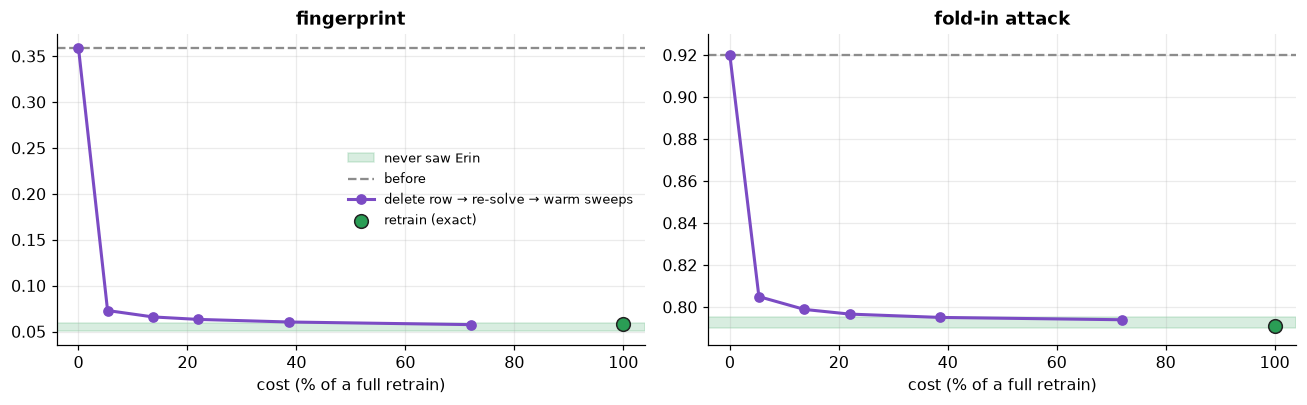

In [8]:
# Step 4: every option against the gold band (✅ = inside mean ± 2 std of the 8 models that never saw Erin)
cols = ["fingerprint", "her pages", "fold-in attack", "recall@10 (others)"]
T = pd.DataFrame({name: measure(m) for name, (m, _) in options.items()}).T
inside = (T[cols] - band_mean[cols]).abs() <= band_half[cols]
T["cost (% of retrain)"] = [100 * c / FULL for _, c in options.values()]
show = T.copy()
for c in cols:
    show[c] = [f"{v:.3f} {'✅' if ok else '❌'}" for v, ok in zip(T[c], inside[c])]
show["cost (% of retrain)"] = T["cost (% of retrain)"].map(lambda v: "" if np.isnan(v) else f"{v:.0f}%")
print("gold band :", "  ".join(f"{c} {band_mean[c]:.3f} ± {band_half[c]:.3f}" for c in cols)); print()
print(show.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, c in zip(axes, ["fingerprint", "fold-in attack"]):
    approx = [n for n in options if n not in ("before", "retrain from scratch (exact)")]
    ax.axhspan(band_mean[c] - band_half[c], band_mean[c] + band_half[c], color=viz.RETRAIN, alpha=0.18, label="never saw Erin")
    ax.axhline(T.loc["before", c], color=viz.ORIGINAL, ls="--", lw=1.5, label="before")
    ax.plot(T.loc[approx, "cost (% of retrain)"], T.loc[approx, c], "o-", color=viz.METHOD, lw=2, label="delete row → re-solve → warm sweeps")
    ax.scatter([100], [T.loc["retrain from scratch (exact)", c]], s=80, color=viz.RETRAIN, edgecolor=viz.INK, zorder=3, label="retrain (exact)")
    ax.set_xlabel("cost (% of a full retrain)"); ax.set_title(c); ax.set_xlim(-4, 104)
axes[0].legend(fontsize=8.5)
lo = band_mean["fold-in attack"] - 4 * band_half["fold-in attack"]
axes[1].set_ylim(lo, T.loc["before", "fold-in attack"] + 0.01)
plt.tight_layout(); plt.show()

Three things to notice.

- **Deleting her row changes nothing the public can see.** The fingerprint, her pages and the attack are exactly the
  same as before. Her own numbers were only used to recommend films *to her*. What she taught the model sits in the
  film numbers. "Deleting is not forgetting" (Problem 4), in a recommender.
- **One cheap update does most of the work.** Re-solving the films costs about 5% of a retrain and closes more than
  90% of the gap on every measurement. Like the Newton step in Problem 2, a well-chosen formula makes a cheap update
  a good one.
- **But "most of the way" is not "inside the band".** The attack can still find her. The other users' numbers were
  learned from film numbers that included her, and it takes many more rounds of training to wash that out. Every check
  passes only after 8 extra rounds, which costs 72% of a full retrain. (On the way, one check can pass by luck, like
  "her pages" after one round. That is why we need *all* checks to pass, as in Problem 11.)

#### Step 4b : Exact by design - splitting users into shards (RecEraser)

In Problem 7, the fix for "retraining is too expensive" was SISA : split the users into groups (shards), train one model
per shard, and when someone leaves, retrain only their shard. RecEraser (Chen et al. 2022) does this for
recommenders. Let's see what it costs.

In [9]:
# Step 4b: SISA for matrix factorisation - each user belongs to one shard; their recommendations come from that shard
class UserShards:
    def __init__(self, n_shards, seed=0):
        self.S = n_shards
        self.shard = np.random.default_rng(seed).integers(0, n_shards, N_USERS)
    def fit(self, R):
        self.models = [rs.ImplicitALS(seed=s).fit(R * (self.shard == s)[:, None]) for s in range(self.S)]
        return self
    def scores(self, users):
        return np.stack([self.models[self.shard[u]].scores([u])[0] for u in users])

rows = {}
for S in [1, 2, 4, 8]:
    sh = UserShards(S).fit(R)
    users_in_shard = int((sh.shard == sh.shard[ERIN]).sum())
    rows[f"{S} shard{'s' if S > 1 else ''}"] = {"recall@10 (others)": rs.recall_at_k(sh, R, R_test, users=others),
                                                "cost to forget Erin (% of retrain)": 100 * als.sweeps * (users_in_shard + N_FILMS) / FULL}
rows["item-kNN, subtract (exact)"] = {"recall@10 (others)": rs.recall_at_k(knn_u, R, R_test, users=others),
                                      "cost to forget Erin (% of retrain)": 100 * cells / rs.ItemKNN.fit_cost(R)}
print(pd.DataFrame(rows).T.round(3).to_string())

                            recall@10 (others)  cost to forget Erin (% of retrain)
1 shard                                  0.422                             100.000
2 shards                                 0.396                              83.314
4 shards                                 0.370                              73.714
8 shards                                 0.345                              68.800
item-kNN, subtract (exact)               0.347                               0.268


For the digit classifier in Problem 7, shards cost a little accuracy. For a recommender they cost a lot, for two
reasons.

1. **A recommender needs other people.** It works by finding people with similar taste. A shard with one eighth of the
   users sees one eighth of the "watched together" links, so every shard recommends worse. With 8 shards, recall falls
   to about the level of plain item-kNN.
2. **Splitting the users does not split the films.** Every shard still has to learn numbers for all 1,682 films. So
   retraining one shard out of eight still costs about two thirds of a full retrain.

Meanwhile item-kNN, a 25-year-old method, forgets *exactly* for about a quarter of a percent of its build cost. If you
must be able to delete people, the "weaker" model can be the better choice. (RecEraser wins back some quality with
smarter ways of splitting and combining shards, but the film side still has to be learned in every shard.)

#### Step 5 : Prove it - and attack the deletion itself

The exact methods pass every check above. Now a trap that is special to recommenders. The "also watched" pages are
public, and they change when Erin is deleted. Anyone can save every page before and after (a web crawler, a rival
company, a journalist). Then they look at **which pages changed the most**. Calandrino et al. (2011) used this trick on
real sites, including Amazon, to work out what single customers had bought. Chen et al. (2021) pointed out that
unlearning gives attackers exactly this kind of before-and-after pair.

The attacker guesses 186 films as "Erin's". We score them by **precision** : the share of guesses that are right. A
random guess gets about 11%.

In [10]:
# Step 5a: the diff attack - guess Erin's films from how much each film's public page changed
chance = len(erin) / N_FILMS

def attack(before, after):
    return rs.precision_at(rs.diff_attack(rs.also_watched(before), rs.also_watched(after)), erin)

exact_als = options["retrain from scratch (exact)"][0]
results = {
    "item-kNN, exact subtraction (similarity scores visible)": rs.precision_at(np.abs(knn.similarity() - knn_u.similarity()).sum(1), erin),
    "item-kNN, exact subtraction (top-10 lists only)": attack(knn, knn_u),
    "ALS, re-solve the films once": attack(als, options["re-solve the films once"][0]),
    "ALS, retrain from scratch (same seed)": attack(als, exact_als),
    "ALS, retrain from scratch (new seed)": attack(als, rs.ImplicitALS(seed=7).fit(R_without)),
}
print(f"The attacker names {len(erin)} films as 'Erin's'. Share that really are hers (chance: {chance:.0%}):\n")
print(pd.Series(results).map("{:.0%}".format).to_string())

The attacker names 186 films as 'Erin's'. Share that really are hers (chance: 11%):

item-kNN, exact subtraction (similarity scores visible)    100%
item-kNN, exact subtraction (top-10 lists only)             42%
ALS, re-solve the films once                                39%
ALS, retrain from scratch (same seed)                       39%
ALS, retrain from scratch (new seed)                        31%


If the service shows similarity *scores* (some websites and APIs do), the exact subtraction gives away Erin's
**whole** history : the only films whose scores changed are hers. With only the top-10 lists visible, the attacker is
still right about 4 times more often than chance. And look at the last rows : **retraining from scratch leaks too**.
"Exact" means the model *after* the deletion is clean. The *difference* between before and after is new information,
and it is about the person who left.

We try three defences on the item-kNN pages :

1. **Delete people in batches** (Problem 17 did this to save money) : many people's pages change at once, so it is
   harder to tell who caused what.
2. **A minimum-support rule** : only show a pair of films if at least `m` people watched both. Then no public list is
   ever based on one person.
3. **Fresh random noise** : each time the pages are refreshed, add a little random noise to every "watched together"
   count, and only show a pair if its noisy count is high enough (`rs.noisy_also_watched`). Recommendations to each
   user still use the exact model. Only the public pages get noise.

                       item-kNN ALS (retrain)
users deleted together                       
1                           42%           39%
10                          38%           39%
50                          35%           34%
150                         25%           23%



                                   attacker precision popular pages kept slots resting on one person (true count)
exact pages                                       42%               100%                                    4,578
minimum support m = 2                             63%               100%                                        0
noise 1, shown if noisy count ≥ 3                 11%                58%                                    3,853
noise 1, shown if noisy count ≥ 5                  9%                72%                                    2,978
noise 2, shown if noisy count ≥ 10                 8%                46%                                    2,731


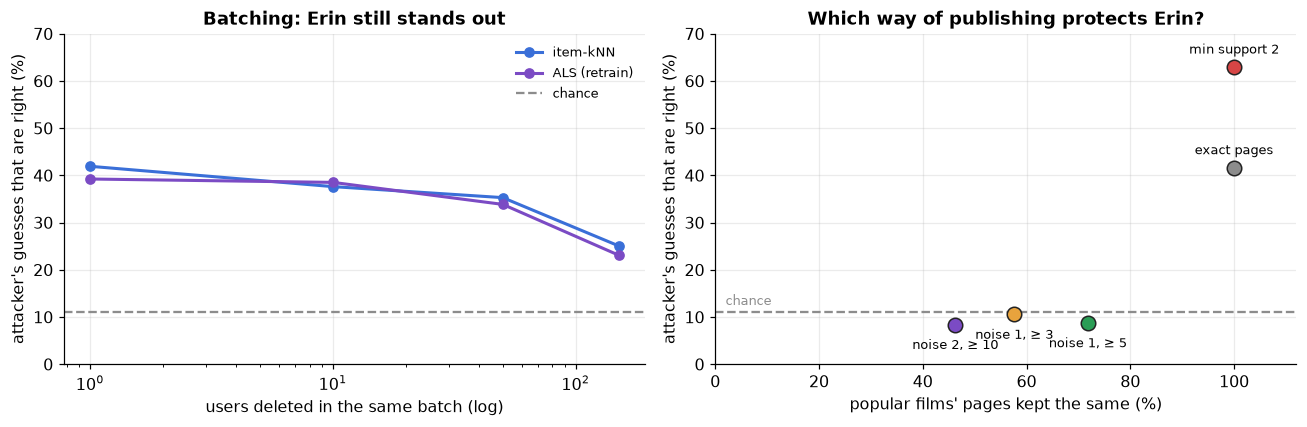

In [11]:
# Step 5b: three defences against the diff attack
rng = np.random.default_rng(1)
batch = {"item-kNN": {}, "ALS (retrain)": {}}
for B in [1, 10, 50, 150]:
    pk, pa = [], []
    for rep in range(3 if B > 1 else 1):
        gone = np.r_[ERIN, rng.choice(others, B - 1, replace=False)]
        k1 = rs.ItemKNN().fit(R); k1.unlearn_users(gone); pk.append(attack(knn, k1))
        Rb = R.copy(); Rb[gone] = 0; pa.append(attack(als, rs.ImplicitALS(seed=0).fit(Rb)))
    batch["item-kNN"][B], batch["ALS (retrain)"][B] = np.mean(pk), np.mean(pa)
print(pd.DataFrame(batch).map("{:.0%}".format).rename_axis("users deleted together").to_string()); print()

popular = np.flatnonzero(audience >= 50)
def page_quality(published):
    # share of a popular film's exact page that survives in the published one
    return np.mean([len(set(published[i]) & set(pages[i]) - {-1}) / 10 for i in popular])

def lone_slots(published):
    return sum(1 for i, row in enumerate(published) for j in row if j >= 0 and knn.G[i, j] == 1)

releases = {"exact pages": lambda Rm, seed: rs.also_watched(rs.ItemKNN().fit(Rm)),
            "minimum support m = 2": lambda Rm, seed: rs.also_watched(rs.ItemKNN(min_support=2).fit(Rm)),
            "noise 1, shown if noisy count ≥ 3": lambda Rm, seed: rs.noisy_also_watched(rs.ItemKNN().fit(Rm), 1, 3, seed),
            "noise 1, shown if noisy count ≥ 5": lambda Rm, seed: rs.noisy_also_watched(rs.ItemKNN().fit(Rm), 1, 5, seed),
            "noise 2, shown if noisy count ≥ 10": lambda Rm, seed: rs.noisy_also_watched(rs.ItemKNN().fit(Rm), 2, 10, seed)}
SHORT = ["exact pages", "min support 2", "noise 1, ≥ 3", "noise 1, ≥ 5", "noise 2, ≥ 10"]
defence = {}
for name, publish in releases.items():
    precs, quals = [], []
    for rep in range(3):
        before, after = publish(R, 10 + rep), publish(R_without, 100 + rep)     # two releases, fresh noise each
        precs.append(rs.precision_at(rs.diff_attack(before, after), erin, seed=rep)); quals.append(page_quality(before))
    defence[name] = {"attacker precision": np.mean(precs), "popular pages kept": np.mean(quals),
                     "slots resting on one person (true count)": lone_slots(before)}
print(pd.DataFrame(defence).T.to_string(formatters={"attacker precision": "{:.0%}".format, "popular pages kept": "{:.0%}".format,
                                                     "slots resting on one person (true count)": "{:,.0f}".format}))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for name, c in [("item-kNN", viz.RETAIN), ("ALS (retrain)", viz.METHOD)]:
    a1.plot(list(batch[name]), [100 * v for v in batch[name].values()], "o-", color=c, lw=2, label=name)
a1.axhline(100 * chance, color=viz.ORIGINAL, ls="--", label="chance"); a1.set_xscale("log")
a1.set_ylim(0, 70); a1.set_xlabel("users deleted in the same batch (log)"); a1.set_ylabel("attacker's guesses that are right (%)")
a1.set_title("Batching: Erin still stands out"); a1.legend(fontsize=8.5)
for d, label, c in zip(defence.values(), SHORT, [viz.ORIGINAL, viz.FORGET, viz.ACCENT, viz.RETRAIN, viz.METHOD]):
    a2.scatter(100 * d["popular pages kept"], 100 * d["attacker precision"], s=90, color=c, edgecolor=viz.INK, zorder=3)
    a2.annotate(label, (100 * d["popular pages kept"], 100 * d["attacker precision"]), xytext=(0, -16 if "noise" in label else 9),
                textcoords="offset points", ha="center", fontsize=8.5)
a2.axhline(100 * chance, color=viz.ORIGINAL, ls="--"); a2.text(2, 100 * chance + 1.5, "chance", color=viz.ORIGINAL, fontsize=8.5)
a2.set_xlim(0, 112); a2.set_ylim(0, 70)
a2.set_xlabel("popular films' pages kept the same (%)"); a2.set_ylabel("attacker's guesses that are right (%)")
a2.set_title("Which way of publishing protects Erin?")
plt.tight_layout(); plt.show()

**Batching helps the crowd, not the unusual person.** Deleting 150 users together cuts the attacker's success by about
40%, but it is still twice chance. Typical users watch popular films, and their pages hardly change. Erin's rare films
still have the most-changed pages, because she was most of their audience.

**The minimum-support rule makes the attack *worse*.** It does remove every slot based on one person, so the leak we saw
in Step 2 is gone. But when Erin is deleted, every pair she shared with exactly one other person drops from 2 viewers to
1. Those pairs fall below the rule and vanish from the pages, and the pages that lost entries are exactly her films. A
fixed rule creates a sharp edge, and Erin sits right on it.

**Fresh noise beats the attack.** With random noise, the before and after pages differ everywhere, a little, at random.
Erin's deletion gets lost in that, and the attacker is back to guessing. The cost is on the public pages, not on the
recommendations : popular films keep most, but not all, of their true page. More noise means more protection and
worse pages. (Some pairs shown are still based on one person. But such a pair now appears only a few times more often
than a pair nobody watched, so no single slot proves anything.)

Two warnings. The noise must be **new** every time the pages are refreshed. If you reuse the same noise, the difference
is exact again. And every refresh gives away a little, because an attacker who averages many refreshes averages the
noise away. Working out exactly how much noise is enough, for how many refreshes, is what **differential privacy**
does.

> 🔴 **For practitioners :** a recommender's outputs often travel far from the model : product pages, "trending" lists,
> marketing emails, item embeddings shared with the search or ads teams. Each one is a downstream artefact in Problem
> 17's lineage registry and needs the same care. Three rules do most of the work. (1) Keep the **private** part
> (recommendations shown to one user) separate from the **public** part (pages and lists), and treat the public part
> as a data release. (2) Publish the public part with fresh noise and a privacy budget, never from exact counts.
> (3) Refresh public lists on a schedule that mixes deletions with normal new activity, so one deletion never shows up
> as a clean before-and-after pair. For user and item embeddings, the fold-in attack above is a cheap check to run
> after every approximate update.

----
#### OUTCOME :

| Model | How Erin is removed | Exact? | Cost | Inside the gold band? | Public pages after |
|---|---|---|---|---|---|
| Item-kNN | subtract her "watched together" counts | ✅ bit for bit | **0.3%** of a rebuild | ✅ always | her lone pairs gone |
| Matrix factorisation | delete her user vector | ❌ | 0 | ❌ nothing changes | unchanged |
| Matrix factorisation | re-solve the films once (+ more rounds) | ❌ | 5% (up to most of a retrain) | ❌ close, only at high cost | mostly cleaned |
| Matrix factorisation | retrain from scratch | ✅ | 100% | ✅ | cleaned |
| Matrix factorisation, shards | retrain her shard | ✅ | about two thirds with 8 shards | ✅ | cleaned, but worse recommendations |
| Any of the above | compare public pages before and after | - | - | - | ⚠️ shows her films; batching and a fixed rule do not stop it, fresh noise does |

#### Key Takeaways :

- In a recommender, your data lives in the **links between films**, and other people see those links. Deleting your
  account or your vector removes none of them.
- **Item-kNN is a sum**, so forgetting a user is a subtraction : exact, almost free, bit for bit.
- **Matrix factorisation ties everyone together.** One cheap update removes most of a user, but exact forgetting needs
  a retrain, and splitting users into shards costs recommendation quality.
- Checking quality for everyone else is the **wrong** test. It did not move for any method, even the ones that left
  Erin on every page.
- **A deletion is itself a piece of news.** Comparing public pages before and after shows what was deleted. Batching
  hides typical users but not unusual ones, and a fixed minimum-support rule makes it worse. **Fresh noise on what you
  publish** is what stops it.

#### TASK :
1. Pick a *typical* user instead of Erin (one whose films have a median audience above 100). Re-run Steps 2-5. Is
   there anything left to remove, and how well does the before-and-after attack do?
2. Publish the noisy pages twice with the **same** seed, before and after the deletion. How good is the attacker now?
   Then publish 20 refreshes with new seeds and let the attacker average them, before and after. How many refreshes
   until the attack works again?
3. Add new users without retraining : keep the film numbers fixed and solve only the new user's numbers
   (`als.solve`). With that design, which deletions become exact for free, and which do not?
4. RecEraser groups similar users into the same shard, instead of splitting at random. Group users with k-means on
   their rows of `R` and compare recall with the random split at 4 and 8 shards. If Erin's shard is full of people
   like her, who pays for the better recall?

#### ❓ Open question → Problem 19
This problem used two old and simple recommenders, and Problems 6-11 used eight unlearning methods. The research world
has dozens more, and every new paper says its method works. **If we put many of them, old and new, through the same
fixed exam, do the new ones actually do better?** That is Problem 19.